# Amazon Bestselling Books Analysis

**Beginner data analysis project | Python, pandas, matplotlib, seaborn**

In this project, we will explore the Amazon Top 50 Bestselling Books dataset (2009-2019). We will load a CSV, inspect and clean the data, answer questions about authors, genres, ratings, and reviews, then create charts.

## Before you start

1. In VS Code, choose **Select Kernel** and select the project environment at `.venv/Scripts/python.exe`.
2. Download the dataset CSV, commonly named `bestsellers with categories.csv`.
3. Put the CSV in the same folder as this notebook.
4. Run the code cells from top to bottom using **Run All** or the play button on each cell.

The notebook will tell you if the CSV is missing. It will not make up results; the findings depend on the dataset you provide.

## 1. Import Required Libraries

We will use pandas to work with table-shaped data. Matplotlib and seaborn help us create charts.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load the Amazon Bestsellers Dataset

`read_csv()` reads a CSV file into a pandas DataFrame, which is like a spreadsheet we can analyze. This dataset usually includes columns such as `Name`, `Author`, `User Rating`, `Reviews`, `Price`, `Year`, and `Genre`.

In [3]:
csv_name = "bestsellers with categories.csv"
candidate_paths = [Path(csv_name), Path("amazon-book-analysis") / csv_name]
csv_path = next((path for path in candidate_paths if path.exists()), None)

if csv_path is None:
    raise FileNotFoundError(
        f"Could not find '{csv_name}'. Put the CSV beside this notebook. "
        f"Current working folder: {Path.cwd()}"
    )

book = pd.read_csv(csv_path)
required_columns = ["Name", "Author", "User Rating", "Reviews", "Price", "Year", "Genre"]
missing_columns = [column for column in required_columns if column not in book.columns]
if missing_columns:
    raise ValueError(f"The CSV is missing expected columns: {missing_columns}")

print(f"Loaded {len(book)} rows from: {csv_path}")
book.head()

Loaded 550 rows from: bestsellers with categories.csv


,Name,Author,User Rating,Reviews,Price,Year,Genre
0,10-Day Green Smoothie Cleanse,JJ Smith,4.7,17350,8,2016,Non Fiction
1,11/22/63: A Novel,Stephen King,4.6,2052,22,2011,Fiction
2,12 Rules for Life: An Antidote to Chaos,Jordan B. Peterson,4.7,18979,15,2018,Non Fiction
3,1984 (Signet Classics),George Orwell,4.7,21424,6,2017,Fiction
4,"5,000 Awesome Facts (About Everything!) (Natio...",National Geographic Kids,4.8,7665,12,2019,Non Fiction


## 3. Explore the Dataset Structure

Before analyzing data, check what each row and column looks like. `shape` gives the number of rows and columns, `info()` shows column types and non-missing values, and `describe()` summarizes numeric columns.

In [4]:
print("Rows and columns:", book.shape)
book.info()

print("\nNumeric summary:")
book.describe()

Rows and columns: (550, 7)
<class 'pandas.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         550 non-null    str    
 1   Author       550 non-null    str    
 2   User Rating  550 non-null    float64
 3   Reviews      550 non-null    int64  
 4   Price        550 non-null    int64  
 5   Year         550 non-null    int64  
 6   Genre        550 non-null    str    
dtypes: float64(1), int64(3), str(3)
memory usage: 30.2 KB

Numeric summary:


,User Rating,Reviews,Price,Year
count,550.000000,550.000000,550.000000,550.000000
mean,4.618364,11953.281818,13.100000,2014.000000
std,0.226980,11731.132017,10.842262,3.165156
min,3.300000,37.000000,0.000000,2009.000000
25%,4.500000,4058.000000,7.000000,2011.000000
50%,4.700000,8580.000000,11.000000,2014.000000
75%,4.800000,17253.250000,16.000000,2017.000000
max,4.900000,87841.000000,105.000000,2019.000000


## 4. Clean and Prepare the Data

We will check missing values and exact duplicate rows. We remove only exact duplicate rows: a book title can appear in more than one year, so removing rows by title alone could throw away valid records. Finally, we convert the columns used for calculations to numeric types.

In [5]:
book_clean = book.copy()

print("Missing values before cleaning:")
print(book_clean.isna().sum())
print("Exact duplicate rows:", book_clean.duplicated().sum())

book_clean = book_clean.drop_duplicates().copy()

for column in ["User Rating", "Reviews", "Price", "Year"]:
    book_clean[column] = pd.to_numeric(book_clean[column], errors="coerce")

for column in ["Name", "Author", "Genre"]:
    book_clean[column] = book_clean[column].astype("string").str.strip()

print("\nRows after removing exact duplicates:", len(book_clean))
print("Missing values after cleaning:")
book_clean.isna().sum()

Missing values before cleaning:
Name           0
Author         0
User Rating    0
Reviews        0
Price          0
Year           0
Genre          0
dtype: int64
Exact duplicate rows: 0

Rows after removing exact duplicates: 550
Missing values after cleaning:


Name           0
Author         0
User Rating    0
Reviews        0
Price          0
Year           0
Genre          0
dtype: int64

## 5. Analyze Top Authors

`value_counts()` counts how often each author appears. Here, a count means appearances in the dataset, not necessarily different book titles.

In [6]:
top_authors = book_clean["Author"].value_counts().head(10)
top_authors.rename_axis("Author").reset_index(name="Bestseller appearances")

,Author,Bestseller appearances
0,Jeff Kinney,12
1,Suzanne Collins,11
2,Rick Riordan,11
3,Gary Chapman,11
4,American Psychological Association,10
5,Dr. Seuss,9
6,Gallup,9
7,Rob Elliott,8
8,Stephenie Meyer,7
9,Dav Pilkey,7


## 6. Analyze Most Popular Genres

`groupby()` lets us group rows by genre and calculate a summary for each group. First, count the bestseller appearances for each genre.

In [7]:
genre_counts = book_clean["Genre"].value_counts()
genre_counts.rename_axis("Genre").reset_index(name="Bestseller appearances")

,Genre,Bestseller appearances
0,Non Fiction,310
1,Fiction,240


## 7. Find Books with Highest Ratings

The first table sorts by user rating, then by review count to make ties easier to compare. The second table finds books with the most reviews. A large review count is not the same thing as a high rating, so we examine both.

In [8]:
book_columns = ["Name", "Author", "User Rating", "Reviews", "Price", "Year", "Genre"]

highest_rated = book_clean.dropna(subset=["User Rating"]).sort_values(
    ["User Rating", "Reviews"], ascending=[False, False]
)
highest_rated[book_columns].head(10)

,Name,Author,User Rating,Reviews,Price,Year,Genre
245,"Oh, the Places You'll Go!",Dr. Seuss,4.9,21834,8,2012,Fiction
246,"Oh, the Places You'll Go!",Dr. Seuss,4.9,21834,8,2013,Fiction
247,"Oh, the Places You'll Go!",Dr. Seuss,4.9,21834,8,2014,Fiction
248,"Oh, the Places You'll Go!",Dr. Seuss,4.9,21834,8,2015,Fiction
249,"Oh, the Places You'll Go!",Dr. Seuss,4.9,21834,8,2016,Fiction
250,"Oh, the Places You'll Go!",Dr. Seuss,4.9,21834,8,2017,Fiction
251,"Oh, the Places You'll Go!",Dr. Seuss,4.9,21834,8,2018,Fiction
252,"Oh, the Places You'll Go!",Dr. Seuss,4.9,21834,8,2019,Fiction
153,Harry Potter and the Chamber of Secrets: The I...,J.K. Rowling,4.9,19622,30,2016,Fiction
187,Jesus Calling: Enjoying Peace in His Presence ...,Sarah Young,4.9,19576,8,2011,Non Fiction


In [9]:
most_reviewed = book_clean.dropna(subset=["Reviews"]).nlargest(10, "Reviews")
most_reviewed[book_columns]

,Name,Author,User Rating,Reviews,Price,Year,Genre
534,Where the Crawdads Sing,Delia Owens,4.8,87841,15,2019,Fiction
382,The Girl on the Train,Paula Hawkins,4.1,79446,18,2015,Fiction
383,The Girl on the Train,Paula Hawkins,4.1,79446,7,2016,Fiction
32,Becoming,Michelle Obama,4.8,61133,11,2018,Non Fiction
33,Becoming,Michelle Obama,4.8,61133,11,2019,Non Fiction
135,Gone Girl,Gillian Flynn,4.0,57271,10,2012,Fiction
136,Gone Girl,Gillian Flynn,4.0,57271,10,2013,Fiction
137,Gone Girl,Gillian Flynn,4.0,57271,9,2014,Fiction
365,The Fault in Our Stars,John Green,4.7,50482,13,2012,Fiction
366,The Fault in Our Stars,John Green,4.7,50482,13,2013,Fiction


## 8. Visualize Key Insights

A bar chart makes category comparisons easier to see. These charts show the number of bestseller appearances by genre and the average user rating by genre.

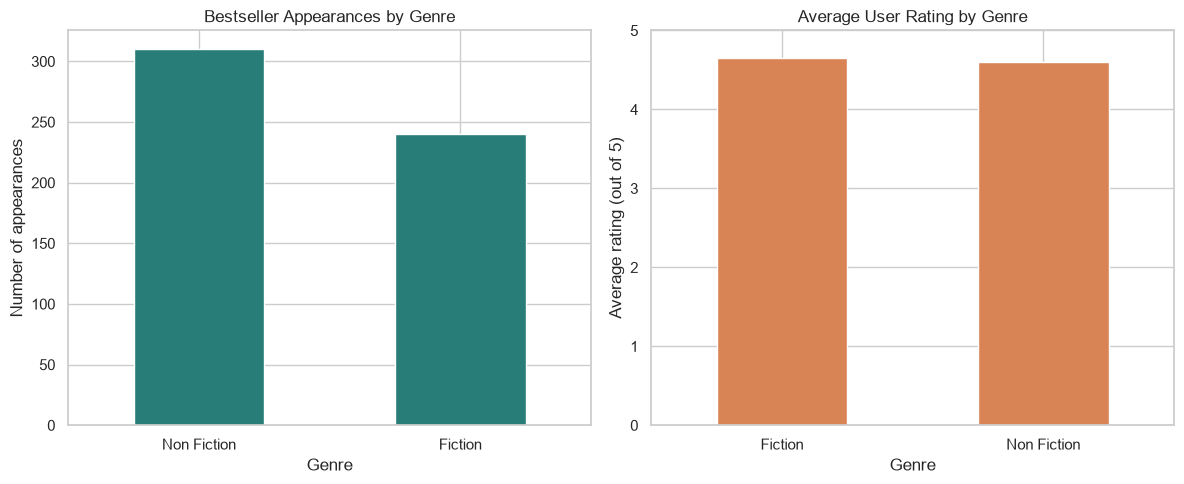

In [10]:
average_rating_by_genre = (
    book_clean.groupby("Genre")["User Rating"].mean().sort_values(ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
genre_counts.plot(kind="bar", color="#287D78", ax=axes[0])
axes[0].set_title("Bestseller Appearances by Genre")
axes[0].set_xlabel("Genre")
axes[0].set_ylabel("Number of appearances")
axes[0].tick_params(axis="x", rotation=0)

average_rating_by_genre.plot(kind="bar", color="#D98455", ax=axes[1])
axes[1].set_title("Average User Rating by Genre")
axes[1].set_xlabel("Genre")
axes[1].set_ylabel("Average rating (out of 5)")
axes[1].tick_params(axis="x", rotation=0)
axes[1].set_ylim(0, 5)

fig.tight_layout()
plt.show()

## Findings

The dataset contains 550 rows and 7 columns. It has no missing values and no exact duplicate rows, so the cleaning step did not remove any records.

- Jeff Kinney has the most bestseller appearances, with 12.
- Non Fiction has 310 appearances (56.4%); Fiction has 240 (43.6%). These are appearances in yearly bestseller lists, not unique titles or total sales.
- Fiction's average user rating is about 4.65 out of 5, compared with about 4.60 for Non Fiction. This is a small descriptive difference, not evidence that genre causes higher ratings.
- The highest rating is 4.9, shared by multiple entries.

## CV Project Description

> Analyzed 550 Amazon bestseller records (2009-2019) using pandas; checked data quality, compared author and genre appearances, examined ratings and review counts, and created visualizations with matplotlib and seaborn.

Be ready to explain what each measure means and how the analysis was performed.